<a href="https://colab.research.google.com/github/AnanyaAsthana/Data-Mining-Warehousing-Lab/blob/main/lab9_dwm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving 06_entropy_information_gain_gini.csv to 06_entropy_information_gain_gini.csv
First 5 rows:
  Record_ID Outlook Humidity    Wind Play
0      E001   Rainy     High    Weak   No
1      E002   Sunny     High    Weak   No
2      E003   Sunny   Normal  Strong  Yes
3      E004   Rainy     High    Weak  Yes
4      E005  Cloudy     High  Strong  Yes

Entropy of Play: 0.9709505944546686

Joint Entropy H(Outlook, Play): 2.399544716940518

Conditional Entropy H(Play|Outlook): 0.9119268496388448

Information Gain: 0.05902374481582373

Mutual Information: 0.05902374481582395

Gini Impurity of Play: 0.48

Weighted Gini after Outlook split: 0.4403559472569515

ATTRIBUTE SELECTION RESULTS
  Attribute  Conditional Entropy  Information Gain  Mutual Information  \
0   Outlook               0.9119            0.0590              0.0590   
1  Humidity               0.9428            0.0281              0.0281   
2      Wind               0.9661            0.0049              0.0049   

   Weighted Gin

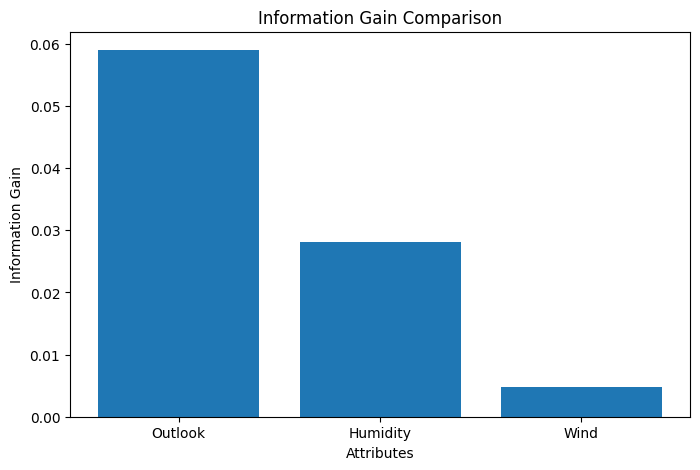


CONCLUSION:
Entropy measures uncertainty in the target.
Information Gain measures reduction in entropy.
Mutual Information measures shared information.
Gini measures impurity of a dataset.
The attribute with maximum Information Gain
is selected as the best splitting attribute.


In [1]:

# EXPERIMENT 7: ENTROPY, INFORMATION GAIN AND GINI INDEX

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load dataset
from google.colab import files
uploaded = files.upload()

df = pd.read_csv('06_entropy_information_gain_gini.csv')

print("First 5 rows:")
print(df.head())


# Target attribute
target = 'Play'

# Calculate entropy
def entropy(series):
    probabilities = series.value_counts(normalize=True)
    return -np.sum(probabilities * np.log2(probabilities))


# Calculate joint entropy
def joint_entropy(x, y):
    joint = pd.DataFrame({
        'X': x,
        'Y': y
    })

    probabilities = joint.value_counts(normalize=True)

    return -np.sum(
        probabilities * np.log2(probabilities)
    )


# Calculate conditional entropy
def conditional_entropy(x, y):
    result = 0

    for value in x.unique():
        subset = y[x == value]

        probability = len(subset) / len(y)

        result += probability * entropy(subset)

    return result


# Calculate Gini impurity
def gini(series):
    probabilities = series.value_counts(normalize=True)

    return 1 - np.sum(probabilities ** 2)


# 1. ENTROPY OF TARGET
H_play = entropy(df[target])

print("\nEntropy of Play:", H_play)


# 2. JOINT ENTROPY
H_joint = joint_entropy(df['Outlook'], df['Play'])

print("\nJoint Entropy H(Outlook, Play):", H_joint)


# 3. CONDITIONAL ENTROPY
H_cond = conditional_entropy(
    df['Outlook'],
    df['Play']
)

print("\nConditional Entropy H(Play|Outlook):", H_cond)


# 4. INFORMATION GAIN
IG = H_play - H_cond

print("\nInformation Gain:", IG)


# 5. MUTUAL INFORMATION
MI = H_play + entropy(df['Outlook']) - H_joint

print("\nMutual Information:", MI)


# 6. GINI IMPURITY
gini_play = gini(df['Play'])

print("\nGini Impurity of Play:", gini_play)


# Weighted Gini after splitting by Outlook
weighted_gini = 0

for value in df['Outlook'].unique():

    subset = df[df['Outlook'] == value]

    weight = len(subset) / len(df)

    weighted_gini += weight * gini(subset['Play'])

print("\nWeighted Gini after Outlook split:", weighted_gini)


# 7. COMPARE ALL ATTRIBUTES

attributes = ['Outlook', 'Humidity', 'Wind']

results = []

for attribute in attributes:

    cond_entropy = conditional_entropy(
        df[attribute],
        df[target]
    )

    information_gain = H_play - cond_entropy

    mutual_info = (
        entropy(df[attribute]) +
        H_play -
        joint_entropy(df[attribute], df[target])
    )

    weighted = 0

    for value in df[attribute].unique():

        subset = df[df[attribute] == value]

        weight = len(subset) / len(df)

        weighted += weight * gini(subset[target])

    results.append({
        'Attribute': attribute,
        'Conditional Entropy': cond_entropy,
        'Information Gain': information_gain,
        'Mutual Information': mutual_info,
        'Weighted Gini': weighted
    })


result_df = pd.DataFrame(results)

print("\nATTRIBUTE SELECTION RESULTS")
print(result_df.round(4))


# 8. BEST ATTRIBUTE
best_attribute = result_df.loc[
    result_df['Information Gain'].idxmax(),
    'Attribute'
]

print("\nBEST ATTRIBUTE FOR SPLITTING:", best_attribute)


# 9. VISUALIZATION
plt.figure(figsize=(8, 5))

plt.bar(
    result_df['Attribute'],
    result_df['Information Gain']
)

plt.xlabel('Attributes')
plt.ylabel('Information Gain')
plt.title('Information Gain Comparison')

plt.show()


# 10. CONCLUSION
print("\nCONCLUSION:")
print("Entropy measures uncertainty in the target.")
print("Information Gain measures reduction in entropy.")
print("Mutual Information measures shared information.")
print("Gini measures impurity of a dataset.")
print("The attribute with maximum Information Gain")
print("is selected as the best splitting attribute.")
